# 10. Learning How Much the Explained Fraction Says

> **Overview.** Parents by error get hogged by noise outputs (notebook 1); error times explained fraction cannot see
> outputs whose learnable part the linear learner misses, which hurts on Asteroids. Can search learn, from what its
> new LTUs achieve, how far to trust the explained fraction, and do well on every problem so far?

**Setup.** Notebook 4's target and learner, on notebooks 4, 5 and 7's problems: 10 improvable outputs sharing 8 target
LTUs, or 4 with 2 of their own, with the other outputs noise, linear or noisy linear; and the needle that moves.
Parents are drawn in proportion to each output's error $L_o$ times:
- nothing (parents by error, notebook 1);
- its explained fraction $e_o$ (notebook 4a);
- **(proposed)** $\max(a + b\,e_o, 0)$, a line fitted over the LTUs search has added: from their parent's explained
  fraction when they were added, to what they achieve for that parent (the error their removal would add there, over
  the parent's error when they were added). Two pseudo-trials at (0, 0) and (1, 1) start it at $a = 0, b = 1$, error
  times explained fraction; with $b = 0$ it would be parents by error. Replaced LTUs' outcomes fade by the replaced
  share, 1/8, per search step.

Against parents drawn uniformly, and an oracle (uniform among the outputs reading target LTUs; for the needle, the
needle). 5 seeds; 500k steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_INPUTS = 400
N_TARGETS = 8                        # target LTUs at first
N_SOURCES = 10                       # inputs each target LTU reads, drawn at random
N_OUTPUTS = 100
N_IMPROVABLE = 10                    # the first outputs, each reading target LTUs at first
OUTPUT_FAN_IN = 4                    # target LTUs each of them reads, drawn at random
OWN_IMPROVABLE, OWN_FAN_IN = 4, 2    # with features of their own: 4 outputs, each reading 2 target LTUs of its own
NOISE_STD = 0.1                      # observation noise on outputs that read target LTUs: the RMSE floor
LINEAR_RMSE = np.sqrt(1 - 2 / np.pi + NOISE_STD ** 2)   # about the best linear learner's RMSE on such an output
N_CHANGES = 8                        # changes (needle problem), one output at a time, alternating: an output changes;
FIRST_CHANGE, CHANGE_EVERY = 100_000, 50_000   # a noise output becomes a target (and an improvable output noise)
N_NEW = 2                            # new target LTUs the changed output reads
N_ALL_TARGETS = N_TARGETS + N_NEW * N_CHANGES

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the LTUs
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
N_LTUS = 32
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects an input whose gradient sum is this many RMS above the rest
FAN_IN = 20                          # a new LTU first reads this many inputs
REPLACED = 4                         # LTUs replaced at each search step, the least useful

# --- Experiment ---
NUM_STEPS = 500_000
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps
UNIFORM, LOSS, EXPLAINED, FITTED, ORACLE = range(5)   # how a new LTU's parent output is drawn
NOISE, LINEAR, NOISY_LINEAR = range(3)                 # kinds of the outputs that do not read target LTUs

## Target

In [3]:
class Target(NamedTuple):
    w: jax.Array                # (N_ALL_TARGETS, N_INPUTS): the target LTUs' weights, +-1 on the inputs they read
    out: jax.Array              # (N_CHANGES + 1, N_OUTPUTS, N_ALL_TARGETS): the outputs' weights on them, by version
    noise_std: jax.Array        # (N_CHANGES + 1, N_OUTPUTS): each output's noise, by version
    needle: jax.Array           # (N_CHANGES + 1,): the newest output reading new target LTUs (-1 before any change)
    linear: jax.Array           # (N_OUTPUTS, N_INPUTS): the other outputs' linear weights, if linear


def make_target(key, kind, own):
    # Version 0: the first N_IMPROVABLE outputs each read OUTPUT_FAN_IN of the first N_TARGETS target LTUs, drawn at
    # random (if own, the first OWN_IMPROVABLE each read OWN_FAN_IN of their own), with random +-1 weights scaled to
    # unit variance, plus noise NOISE_STD. The others are, by kind, noise of unit variance; linear: a linear function of
    # N_SOURCES random inputs, with random +-1 weights scaled to unit variance, plus noise NOISE_STD; or noisy linear:
    # such a function plus noise of unit variance. Each target LTU reads N_SOURCES inputs drawn at random, with random
    # +-1 weights. Change c makes version
    # c + 1: if c is even, an output reading target LTUs, at random, reads the next N_NEW instead (an output changes);
    # if odd, one of them becomes noise of unit variance, and a noise output, at random, reads the next N_NEW (a noise
    # output becomes a target).
    read_key, w_key, out_key, out_w_key, change_key, linear_key, linear_w_key = jax.random.split(key, 7)
    pick = lambda k, shape, n: jnp.argsort(jnp.argsort(jax.random.uniform(k, shape))) < n   # n random entries per row
    w = (jax.random.rademacher(w_key, (N_ALL_TARGETS, N_INPUTS), dtype=float)
         * pick(read_key, (N_ALL_TARGETS, N_INPUTS), N_SOURCES))
    first = jnp.arange(N_OUTPUTS)[:, None] < jnp.where(own, OWN_IMPROVABLE, N_IMPROVABLE)
    fan_in = jnp.where(own, OWN_FAN_IN, OUTPUT_FAN_IN)
    mine = jnp.arange(N_TARGETS) // fan_in == jnp.arange(N_OUTPUTS)[:, None]
    reads = jnp.pad(jnp.where(own, mine, pick(out_key, (N_OUTPUTS, N_TARGETS), OUTPUT_FAN_IN)),
                    ((0, 0), (0, N_ALL_TARGETS - N_TARGETS)))
    out = (jax.random.rademacher(out_w_key, (N_OUTPUTS, N_ALL_TARGETS), dtype=float) * reads * first
           / jnp.sqrt(fan_in))
    noise_std = jnp.where(first[:, 0] | (kind == LINEAR), NOISE_STD, 1.0)
    linear = (jax.random.rademacher(linear_w_key, (N_OUTPUTS, N_INPUTS), dtype=float)
              * pick(linear_key, (N_OUTPUTS, N_INPUTS), N_SOURCES) / np.sqrt(N_SOURCES) * (~first & (kind != NOISE)))
    outs, noise_stds, needles = [out], [noise_std], [jnp.array(-1)]
    for c in range(N_CHANGES):
        sign_key, old_key, new_key = jax.random.split(jax.random.fold_in(change_key, c), 3)
        improvable = (out != 0).any(1)
        targets = jnp.arange(N_ALL_TARGETS)
        new = (targets >= N_TARGETS + N_NEW * c) & (targets < N_TARGETS + N_NEW * (c + 1))
        row = jax.random.rademacher(sign_key, (N_ALL_TARGETS,), dtype=float) * new / np.sqrt(N_NEW)
        old = jax.random.categorical(old_key, jnp.log(improvable))
        if c % 2 == 0:
            needle = old
        else:
            needle = jax.random.categorical(new_key, jnp.log(~improvable))
            out, noise_std = out.at[old].set(0.0), noise_std.at[old].set(1.0)
        out, noise_std = out.at[needle].set(row), noise_std.at[needle].set(NOISE_STD)
        outs, noise_stds, needles = outs + [out], noise_stds + [noise_std], needles + [needle]
    return Target(w, jnp.stack(outs), jnp.stack(noise_stds), jnp.stack(needles), linear)


def sample(target, version, key):
    # One input and its noisy targets, under the given version of the target.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, (target.out[version] @ jnp.where(target.w @ x > 0, 1.0, -1.0) + target.linear @ x
               + target.noise_std[version] * jax.random.normal(noise_key, (N_OUTPUTS,)))

## Learner

Notebook 4's learner. New here: each new LTU remembers its parent's error and explained fraction when it was added,
and `parent_logits` fits a line from the explained fraction to what new LTUs achieve.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the LTUs, each shaped (N_LTUS,).
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each LTU, and of g * h
    error_h_mean: jax.Array


class Net(NamedTuple):
    # w['hidden'] is the LTUs' weights over [inputs, 1 (the bias)], of which each reads those in `reads`; w['output'] is
    # the outputs' weights over [inputs (the linear learner), LTUs, 1].
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    added: jax.Array            # whether the LTUs feed the outputs yet
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each LTU's shadow weight, +-1 on one output (its parent), 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS): each LTU's sums of dL/dz * x_i since its last new connection
    loss_sum: jax.Array         # (N_OUTPUTS,): each output's summed squared error since the last search step
    target_sum: jax.Array       # (N_OUTPUTS,): each output's targets, and their squares, summed likewise
    target_sq_sum: jax.Array
    birth: jax.Array            # (N_LTUS,): its parent's mean squared error when search added it (NaN: the first LTUs)
    birth_fraction: jax.Array   # (N_LTUS,): its parent's explained fraction then
    fit_sums: jax.Array         # (5,): replaced LTUs' count and sums of e, f, e^2, e f (e: birth_fraction, f: outcome),
                                # fading by the replaced share each search step


def init_net(key, target):
    # Each pair of LTUs wired like one target LTU in turn: reading its inputs and the bias, with LeCun uniform weights;
    # their shadow weights +1 and -1, on a random output that reads that target LTU. Every other weight 0.
    w_key, out_key = jax.random.split(key)
    assigned = jnp.arange(N_LTUS) // 2 % N_TARGETS
    reads = jnp.append(target.w[assigned] != 0, jnp.ones((N_LTUS, 1), bool), axis=1)
    fan_in = N_SOURCES
    readers = target.out[0][:, assigned] != 0
    parent = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == parent) * jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, jnp.array(False), OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_INPUTS)),
               *(jnp.zeros(N_OUTPUTS),) * 3, jnp.full(N_LTUS, jnp.nan), jnp.zeros(N_LTUS), jnp.zeros(5))


def add(net):
    # The LTUs start feeding the outputs, the step-sizes of their input weights starting at FAST_STEP_SIZE.
    beta = jnp.where(net.reads.at[:, -1].set(False), jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(added=jnp.array(True), opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def rewire(net, key, replaced, parent_logits, parent, signs):
    # Each `replaced` LTU becomes a new LTU. Its shadow weight, +1 or -1 by slot, goes on its parent, an output drawn
    # with log-probabilities parent_logits. It reads FAN_IN inputs and the bias, the inputs drawn without replacement
    # with probability proportional to the square of the parent's linear weight on each if parent, uniformly otherwise
    # (Gumbel top-k), with LeCun uniform weights, taking the signs of its shadow weight times the parent's linear
    # weights if signs, at step-size FAST_STEP_SIZE. Its output weights are 0, and its statistics, Autostep state and
    # gradient sums fresh.
    out_key, draw_key, w_key = jax.random.split(key, 3)
    sign = jnp.where(jnp.arange(N_LTUS) % 2 == 0, 1.0, -1.0)
    new_parent = jax.random.categorical(out_key, parent_logits, shape=(N_LTUS,))
    shadow = jnp.where(replaced, (jnp.arange(N_OUTPUTS)[:, None] == new_parent) * sign, net.shadow)
    parent_w = shadow.T @ net.w['output'][:, :N_INPUTS]      # each LTU's shadow weight times its parent's linear weights
    scores = jnp.where(parent, jnp.log(parent_w ** 2), 0.0) + jax.random.gumbel(draw_key, parent_w.shape)
    inputs = jnp.argsort(jnp.argsort(-scores)) < FAN_IN
    w = jax.random.uniform(w_key, inputs.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / FAN_IN) * inputs
    w = jnp.where(signs, jnp.abs(w) * jnp.sign(parent_w), w)

    where = {'hidden': replaced[:, None],
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), replaced, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    fast = jnp.append(inputs, jnp.zeros((N_LTUS, 1), bool), axis=1)
    beta = {'hidden': jnp.where(fast, jnp.log(FAST_STEP_SIZE), net.opt.init_beta),
            'output': zeros['output'] + net.opt.init_beta}
    opt = net.opt._replace(beta=reset(net.opt.beta, beta), h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(replaced, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=reset(net.w, {'hidden': jnp.append(w, jnp.zeros((N_LTUS, 1)), axis=1),
                                        'output': zeros['output']}),
                        reads=jnp.where(replaced[:, None], jnp.append(inputs, jnp.ones((N_LTUS, 1), bool), axis=1),
                                        net.reads),
                        opt=opt, stats=stats, shadow=shadow, candidates=jnp.where(replaced[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, each LTU's shadow weight
    # standing in for its weight to its parent in the backward pass while the real one is smaller than 1 in magnitude.
    # Returns the new network and each output's squared error on this sample, before learning from it, which it also
    # adds to loss_sum; adds the targets and their squares to target_sum and target_sq_sum, and dL/dz * x_i to each
    # LTU's gradient sums. `probe` is zero; its gradients are the error arriving at each LTU and dL/dz.

    def loss_fn(w, probe):
        b = ltu((w['hidden'] * net.reads) @ jnp.append(x, 1.0) + probe[1])
        mean = net.stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean)
        h = standardize(b, mean, net.stats.error_mean, net.stats.error_h_mean)
        a = (h + probe[0]) * net.added
        source = jnp.concatenate([x, a, jnp.ones(1)])
        unit_w = w['output'][:, N_INPUTS:-1]
        back = jax.lax.stop_gradient(jnp.where((net.shadow != 0) & (jnp.abs(unit_w) < 1.0), net.shadow, unit_w)) @ a
        prediction = w['output'] @ jax.lax.stop_gradient(source) + back - jax.lax.stop_gradient(back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (jax.lax.stop_gradient(source), jax.lax.stop_gradient(h), mean,
                                                      jax.lax.stop_gradient(prediction - y) ** 2)

    (_, (source, h, mean, squared)), (grads, (error, dz)) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {**grads, 'hidden': grads['hidden'] * net.reads}
    sources = {'hidden': jnp.append(x, 1.0) * net.reads, 'output': jnp.broadcast_to(source, net.w['output'].shape)}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * x, loss_sum=net.loss_sum + squared,
                        target_sum=net.target_sum + y, target_sq_sum=net.target_sq_sum + y ** 2), squared


def grow(net):
    # Each LTU whose largest gradient sum, over the inputs it does not read, is more than GROW_Z times their root mean
    # square connects that input, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = ~net.reads[:, :N_INPUTS]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    grows = jnp.max(sums, 1) > GROW_Z * rms
    new = (jnp.arange(N_INPUTS + 1) == jnp.argmax(sums, 1)[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def usefulness(net):
    # Each LTU's sum of squared outgoing weights: about the increase in the squared error, summed over the outputs, if
    # it were removed (its activity has unit variance).
    return (net.w['output'][:, N_INPUTS:-1] ** 2).sum(0)


def explained_fraction(net):
    # Each output's explained fraction over this search period, (V - L) / V, with L its mean squared error and V its
    # targets' variance (0 if negative).
    loss = net.loss_sum / PERIOD
    variance = net.target_sq_sum / PERIOD - (net.target_sum / PERIOD) ** 2
    return jnp.maximum(variance - loss, 0.0) / jnp.maximum(variance, 1e-30)


def outcomes(net):
    # Each LTU added by search (a trial): its squared weight to its parent, the error its removal would add there, over
    # its parent's mean squared error when it was added; 0 for the first LTUs.
    parent = jnp.argmax(jnp.abs(net.shadow), 0)
    trial = ~jnp.isnan(net.birth)
    own = net.w['output'][parent, N_INPUTS + jnp.arange(N_LTUS)] ** 2
    return trial, jnp.where(trial, own / jnp.maximum(jnp.nan_to_num(net.birth), 1e-30), 0.0)


def fitted_line(net):
    # The least-squares line from the explained fraction e of a trial's parent when it was added to the trial's outcome
    # f, over the replaced trials (fading) and the current ones, plus two pseudo-trials at (0, 0) and (1, 1).
    # Returns (intercept, slope).
    trial, f = outcomes(net)
    e = net.birth_fraction
    sums = net.fit_sums + jnp.array([2.0, 1.0, 1.0, 1.0, 1.0]) + jnp.stack(
        [trial.sum(), (trial * e).sum(), f.sum(), (trial * e * e).sum(), (e * f).sum()])
    slope = (sums[4] - sums[1] * sums[2] / sums[0]) / jnp.maximum(sums[3] - sums[1] ** 2 / sums[0], 1e-30)
    return (sums[2] - slope * sums[1]) / sums[0], slope


def parent_logits(net, rule, needle, improvable):
    # Log-probabilities of each output being a new LTU's parent, in proportion to its mean squared error L since the
    # last search step times: 1 (LOSS); its explained fraction e (EXPLAINED); the fitted line's value at e, where
    # positive (FITTED); uniform; or the oracle: the needle, or uniform among the outputs reading target LTUs before any
    # change. Uniform while all weights are 0.
    def share(weight):
        weight = jnp.maximum(weight, 0.0)
        return jnp.where(weight.sum() > 0, weight / jnp.maximum(weight.sum(), 1e-30), 1 / N_OUTPUTS)

    loss, fraction = net.loss_sum / PERIOD, explained_fraction(net)
    intercept, slope = fitted_line(net)
    oracle = jnp.where(needle >= 0, jnp.arange(N_OUTPUTS) == needle, improvable / improvable.sum())
    return jnp.log(jnp.select([rule == LOSS, rule == EXPLAINED, rule == FITTED, rule == ORACLE],
                              [share(loss), share(loss * fraction), share(loss * (intercept + slope * fraction)),
                               oracle], jnp.full(N_OUTPUTS, 1 / N_OUTPUTS)))

## Training

In [5]:
def pick(condition, a, b):
    # a where condition holds, b otherwise, for networks.
    return jax.tree.map(lambda u, v: jnp.where(condition, u, v), a, b)


def train(net, key, target, rule, changes):
    # NUM_STEPS online network-Autostep steps on samples from `target`, its version changing at FIRST_CHANGE and every
    # CHANGE_EVERY steps after if changes. The LTUs, added at step 0 as new LTUs with parents drawn by `rule`, each grow
    # every WINDOW steps, and every PERIOD steps the REPLACED least useful LTUs are replaced by new ones (their outcomes
    # going into the fitted line's sums), and the outputs' statistics restart. Returns, for each window: the mean
    # squared error over the outputs then reading target LTUs, the needle's (NaN before any change), the share of LTUs
    # whose parent is one of those outputs at its end, and the fitted line's intercept and slope.
    def window(net, inputs):
        index, key = inputs
        version = jnp.where(changes, jnp.clip((index * WINDOW - FIRST_CHANGE) // CHANGE_EVERY + 1, 0, N_CHANGES), 0)
        needle = target.needle[version]
        improvable = (target.out[version] != 0).any(1)
        wire_key, key = jax.random.split(key)
        start = index == 0
        net = pick(start, add(net), net)
        # The first LTUs read random inputs with random signs: their parents have no weights yet.
        net = pick(start, rewire(net, wire_key, jnp.ones(N_LTUS, bool), parent_logits(net, rule, needle, improvable),
                                 False, False), net)
        net, squared = jax.lax.scan(lambda net, k: learn(net, *sample(target, version, k)), net,
                                    jax.random.split(key, WINDOW))
        net = grow(net)
        weakest = jnp.zeros(N_LTUS, bool).at[jnp.argsort(usefulness(net))[:REPLACED]].set(True)
        due = (index + 1) * WINDOW % PERIOD == 0
        trial, f = outcomes(net)
        ended, e = weakest & trial, net.birth_fraction
        net = pick(due, net._replace(
            fit_sums=(1 - REPLACED / N_LTUS) * net.fit_sums + jnp.stack(
                [ended.sum(), (ended * e).sum(), (ended * f).sum(), (ended * e * e).sum(), (ended * e * f).sum()]),
            birth=jnp.where(weakest, jnp.nan, net.birth)), net)
        new = rewire(net, jax.random.fold_in(wire_key, 1), weakest, parent_logits(net, rule, needle, improvable), True,
                     True)
        parent = jnp.argmax(jnp.abs(new.shadow), 0)
        new = new._replace(birth=jnp.where(weakest, (net.loss_sum / PERIOD)[parent], new.birth),
                           birth_fraction=jnp.where(weakest, explained_fraction(net)[parent], new.birth_fraction))
        zero = jnp.zeros(N_OUTPUTS)
        net = pick(due, new._replace(loss_sum=zero, target_sum=zero, target_sq_sum=zero), net)
        squared = squared.mean(0)
        return net, ((squared * improvable).sum() / improvable.sum(),
                     jnp.where(needle >= 0, squared[needle], jnp.nan),
                     jnp.mean(improvable[jnp.argmax(jnp.abs(net.shadow), 0)]), *fitted_line(net))

    n = NUM_STEPS // WINDOW
    return jax.lax.scan(window, net, (jnp.arange(n), jax.random.split(key, n)))[1]


def run(configs):
    # Each (kind, own, changes, rule) of configs on N_SEEDS seeds, vmapped together; seed s gives every run the same
    # target and inputs. Returns {config: (the RMSE over the outputs then reading target LTUs, the needle's RMSE, the
    # share of LTUs whose parent is one of them, the fitted line's intercept and slope), each shaped (seed, window)}.
    kind, own, changes, rule, seed = (jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    targets = jax.vmap(make_target)(keys(2), kind, own)
    nets = jax.vmap(init_net)(keys(0), targets)
    outputs = jax.jit(jax.vmap(train))(nets, keys(1), targets, rule, changes)
    mse, needle, share, intercept, slope = (np.asarray(v).reshape(len(configs), N_SEEDS, -1) for v in outputs)
    return dict(zip(configs, zip(np.sqrt(mse), np.sqrt(needle), share, intercept, slope)))

## Runs

In [6]:
PROBLEMS = [((NOISE, False, False), 'Shared features, other outputs noise'),
            ((LINEAR, False, False), 'Shared features, other outputs linear'),
            ((NOISY_LINEAR, False, False), 'Shared features, other outputs noisy linear'),
            ((NOISE, True, False), 'Features of their own, other outputs noise'),
            ((LINEAR, True, False), 'Features of their own, other outputs linear'),
            ((NOISY_LINEAR, True, False), 'Features of their own, other outputs noisy linear'),
            ((NOISE, False, True), 'A needle that moves (notebook 7)')]
RULES = [('parents uniform (current method)', UNIFORM, 'tab:orange'),
         ('parents by error (notebook 1)', LOSS, 'tab:blue'),
         ('error times explained fraction (notebook 4a)', EXPLAINED, 'mediumorchid'),
         ('error times the fitted line (proposed)', FITTED, 'black'),
         ('oracle', ORACLE, 'tab:green')]
started = perf_counter()
results = run([(*problem, rule) for problem, _ in PROBLEMS for _, rule, _ in RULES])
print(f'{len(results) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

175 runs in 516s


Shared features, other outputs noise
  parents uniform (current method): RMSE averaged over the run 0.336 (by seed [0.317 0.347 0.293 0.398 0.324])
  parents by error (notebook 1): RMSE averaged over the run 0.510 (by seed [0.541 0.539 0.429 0.495 0.544])
  error times explained fraction (notebook 4a): RMSE averaged over the run 0.229 (by seed [0.234 0.225 0.228 0.228 0.231])
  error times the fitted line (proposed): RMSE averaged over the run 0.229 (by seed [0.235 0.225 0.228 0.227 0.231])
  oracle: RMSE averaged over the run 0.231 (by seed [0.229 0.234 0.239 0.227 0.224])
Shared features, other outputs linear
  parents uniform (current method): RMSE averaged over the run 0.302 (by seed [0.333 0.293 0.294 0.294 0.298])
  parents by error (notebook 1): RMSE averaged over the run 0.236 (by seed [0.235 0.244 0.24  0.23  0.234])
  error times explained fraction (notebook 4a): RMSE averaged over the run 0.238 (by seed [0.236 0.244 0.245 0.234 0.232])
  error times the fitted line (proposed

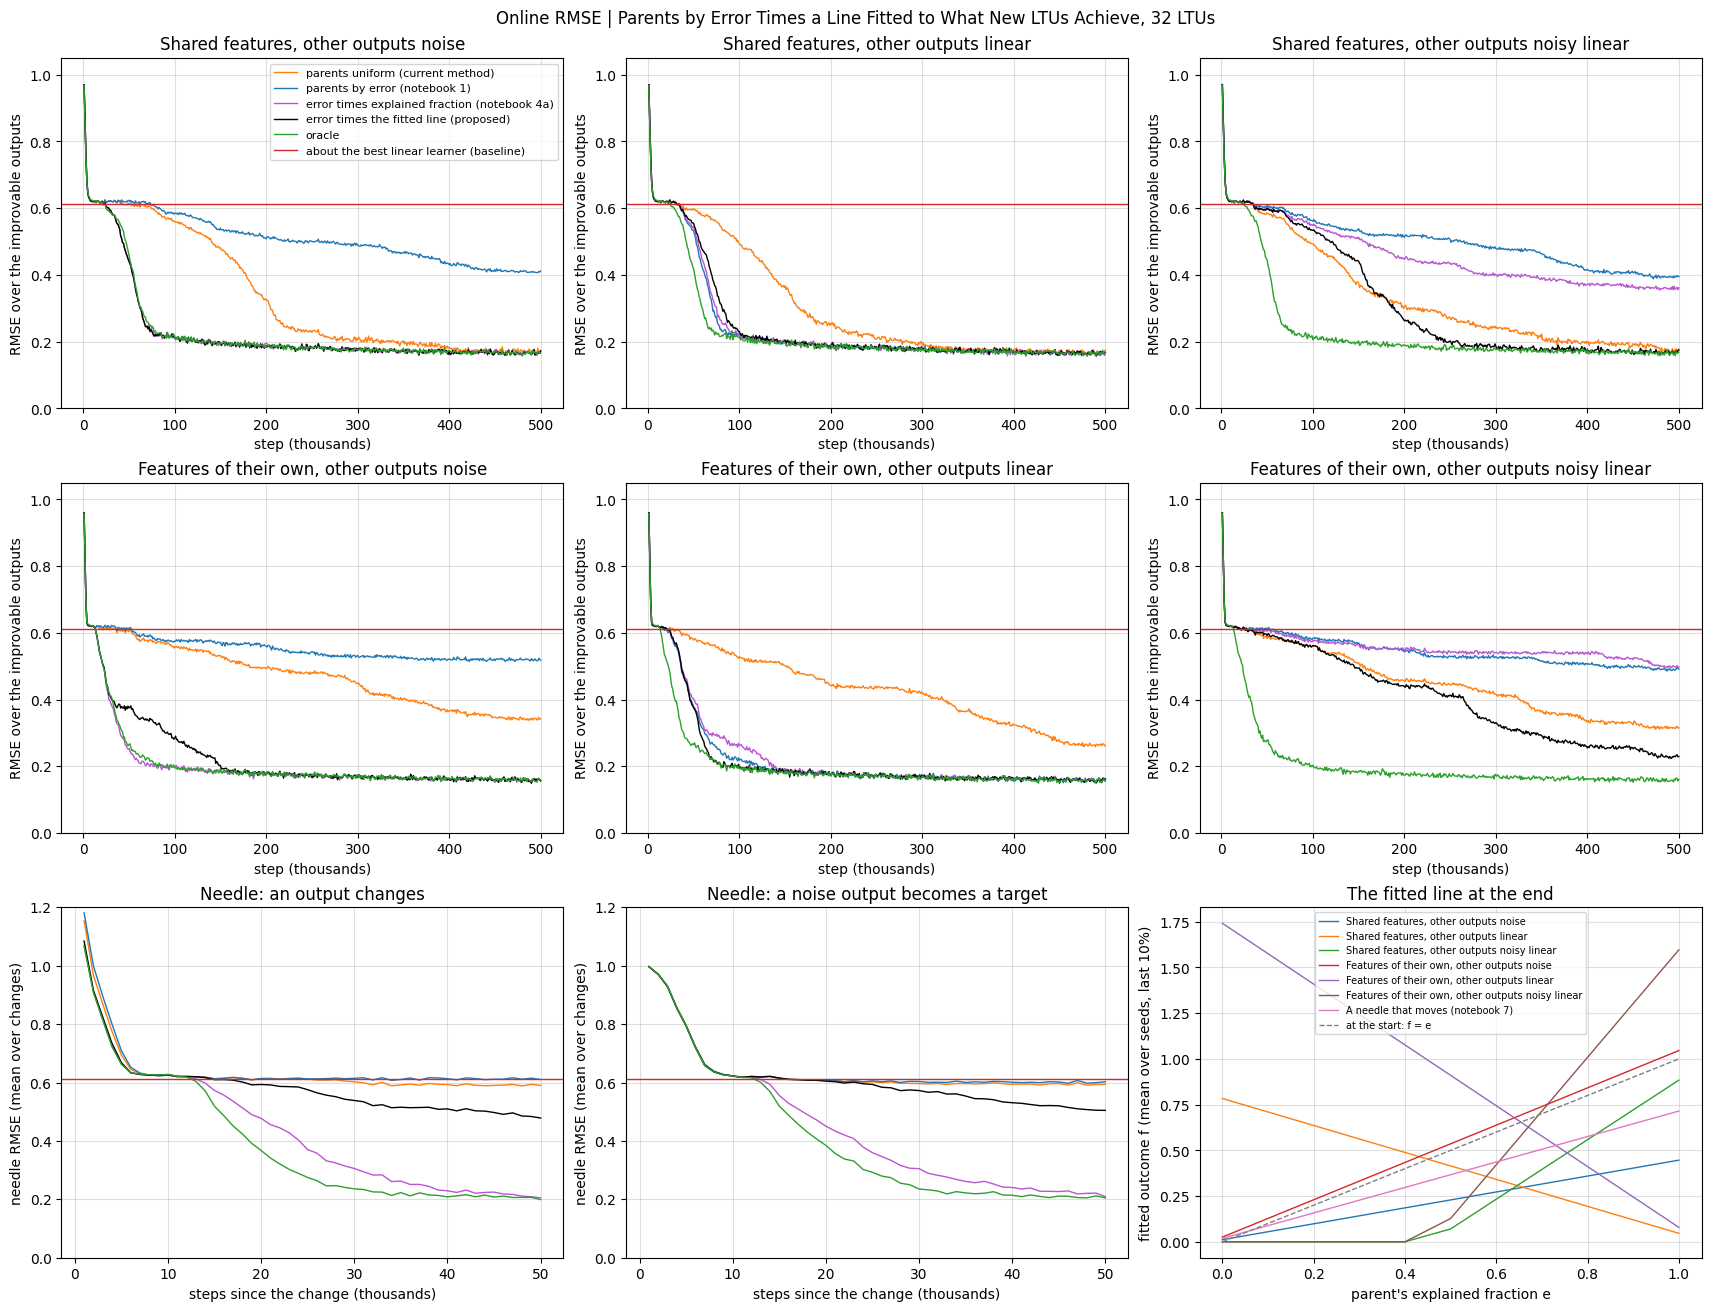

In [7]:
STEPS = (np.arange(NUM_STEPS // WINDOW) + 1) * WINDOW
CHANGES = FIRST_CHANGE + CHANGE_EVERY * np.arange(N_CHANGES)
AFTER = CHANGE_EVERY // WINDOW                  # windows from a change to the next


def after_changes(curve, kind):
    # The windows after each change of this kind (0: an output changes, 1: a noise output becomes a target), shaped
    # (seed, change, window).
    return np.stack([curve[:, c // WINDOW:c // WINDOW + AFTER] for c in CHANGES[kind::2]], 1)


fig, axes = plt.subplots(3, 3, figsize=(17, 13), layout='constrained')
panels = list(axes.flat)
for (problem, title), ax in zip(PROBLEMS[:6], panels[:6]):
    print(title)
    for label, rule, color in RULES:
        rmse = results[(*problem, rule)][0]
        ax.plot(STEPS / 1000, rmse.mean(0), color=color, lw=1, label=label)
        print(f'  {label}: RMSE averaged over the run {rmse.mean():.3f} (by seed {np.round(rmse.mean(1), 3)})')
    ax.axhline(LINEAR_RMSE, color='tab:red', lw=1, label='about the best linear learner (baseline)')
    ax.set(ylim=(0, 1.05), xlabel='step (thousands)', ylabel='RMSE over the improvable outputs', title=title)
problem, title = PROBLEMS[6]
print(title)
for kind, ax in zip(range(2), panels[6:8]):
    for label, rule, color in RULES:
        after = after_changes(results[(*problem, rule)][1], kind)
        ax.plot(np.arange(1, AFTER + 1), after.mean((0, 1)), color=color, lw=1, label=label)
        print(f"  {label}, {['an output changes', 'a noise output becomes a target'][kind]}: needle RMSE over the "
              f'{AFTER}k steps after {after.mean():.3f} (by seed {np.round(after.mean((1, 2)), 3)})')
    ax.axhline(LINEAR_RMSE, color='tab:red', lw=1)
    ax.set(ylim=(0, 1.2), xlabel='steps since the change (thousands)', ylabel='needle RMSE (mean over changes)',
           title=f"Needle: {['an output changes', 'a noise output becomes a target'][kind]}")
fractions = np.linspace(0, 1, 11)
for (problem, title), color in zip(PROBLEMS, plt.cm.tab10(np.arange(len(PROBLEMS)))):
    _, _, _, intercept, slope = results[(*problem, FITTED)]
    a, b = intercept[:, -len(STEPS) // 10:].mean(), slope[:, -len(STEPS) // 10:].mean()
    panels[8].plot(fractions, np.maximum(a + b * fractions, 0), color=color, lw=1, label=title)
    print(f'{title}: fitted line over the last 10%: intercept {a:.3f}, slope {b:.3f}')
panels[8].plot(fractions, fractions, color='gray', ls='--', lw=1, label='at the start: f = e')
panels[8].set(xlabel="parent's explained fraction e", ylabel='fitted outcome f (mean over seeds, last 10%)',
              title='The fitted line at the end')
panels[8].legend(fontsize=7)
for ax in panels:
    ax.grid(alpha=0.4)
panels[0].legend(fontsize=8)
fig.suptitle(f'Online RMSE | Parents by Error Times a Line Fitted to What New LTUs Achieve, {N_LTUS} LTUs')
plt.show()

## Results

RMSE over the improvable outputs averaged over the run (uniform / by error / error times explained fraction /
**fitted line** / oracle):
- Shared features, noise: 0.336 / 0.510 / 0.229 / **0.229** / 0.231
- Shared features, linear: 0.302 / 0.236 / 0.238 / **0.243** / 0.227
- Shared features, noisy linear: 0.329 / 0.500 / 0.456 / **0.314** / 0.229
- Features of their own, noise: 0.471 / 0.553 / 0.203 / **0.225** / 0.206
- Features of their own, linear: 0.433 / 0.221 / 0.227 / **0.216** / 0.203
- Features of their own, noisy linear: 0.449 / 0.544 / 0.554 / **0.406** / 0.206
- Needle, RMSE over the 50k steps after each change (an output changes; a noise output becomes a target): 0.635,
  0.637 / 0.646, 0.641 / 0.429, 0.435 / **0.585, 0.610** / 0.388, 0.403

The fitted line is the only rule here that does no worse than uniform parents on any problem. It is the best of the
rules with noisy linear outputs and with features of their own and linear outputs, and level with error times
explained fraction with shared features and noise outputs. It is behind it with features of their own and noise
outputs (0.225 vs 0.203, from two slow seeds), and far behind it on the needle.

The lines it ends with (last panel) show why:
- **Noise outputs:** through about 0 and rising (intercept 0.01–0.03), like error times explained fraction.
- **Linear outputs:** falling: LTUs tried on the well-explained linear outputs achieve nothing, so the rule comes to
  prefer the less explained, improvable outputs.
- **Noisy linear outputs:** steep, 0 below an explained fraction of about 0.45: it separates the noisy linear outputs
  (about 0.5 explained) from the improvable ones (about 0.63). This works only because the two kinds differ in
  explained fraction here; with equal explained fractions, no line could separate them.
- **The needle:** its intercept stays at about 0.02. That is small, but times 90 noise outputs with error 1, it still
  gives them together about 10 times the needle's weight.

## Details

**A trial** is an LTU added at a search step. Its outcome $f$ is its squared weight to its parent, about the error its
removal would add there (its activity is standardized), over the parent's mean squared error over the search period
before it was added; $e$ is the parent's explained fraction over that period. Trials still in the network count with
their current outcome; when search replaces one, its last outcome joins the fitted sums, which fade by 7/8 per
search step. The first LTUs, wired at step 0 before any error is measured, are not trials.

**The line** is the least-squares fit of $f$ on $e$ over the trials, with two pseudo-trials at $(0, 0)$ and $(1, 1)$
that start it at $f = e$. Its value at each output's current explained fraction, where positive, times its error,
draws parents. The last panel shows the line each problem ends with: its intercept and slope averaged over the
seeds and the last 10% of steps. A flat line would make it parents by error; $f = e$ is error times explained
fraction.

**The problems** are notebook 4's (shared features), notebook 5's (features of their own) and notebook 7's (the
needle, with noise outputs). The targets are drawn differently from those notebooks', so the numbers differ slightly.

**Outcomes on the parent only.** Counting an LTU's usefulness to every output instead would credit a noise output's
LTUs with the small help they give the improvable outputs, and keep the line's value at no explained fraction above
0 even where noise outputs cannot be improved.
"""